# ML Assignment 2: Bank Marketing Classification

**Dataset:** Bank Marketing (UCI), `bank.csv`. Target: `deposit` (yes/no), binary classification.

**Models:** Logistic Regression, Decision Tree, KNN, Naive Bayes (Gaussian), SVM.

**Metrics:** Accuracy, AUC, Precision, Recall, F1, MCC.

Trained models are saved to `model/` and a held-out `test_data.csv` is saved for the Streamlit app.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, matthews_corrcoef, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / 'bank.csv'
MODEL_DIR = BASE_DIR / 'model'
TEST_PATH = BASE_DIR / 'test_data.csv'
TARGET = 'deposit'
RANDOM_STATE = 42
MODEL_DIR.mkdir(exist_ok=True)

## 1. Load and inspect the dataset

In [2]:
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
print('Features:', df.shape[1] - 1)
print(df[TARGET].value_counts())
df.head()

Shape: (11162, 17)
Features: 16
deposit
no     5873
yes    5289
Name: count, dtype: int64


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


## 2. Split features and target, then save the test split

In [3]:
X = df.drop(columns=[TARGET])
y = (df[TARGET].str.strip().str.lower() == 'yes').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

test_df = X_test.copy()
test_df[TARGET] = df.loc[X_test.index, TARGET]
test_df.to_csv(TEST_PATH, index=False)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (8929, 16) Test: (2233, 16)


## 3. Preprocessing and model definitions

In [4]:
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=7),
    'Naive Bayes': GaussianNB(),
    'Support Vector Machine': SVC(probability=True, random_state=RANDOM_STATE),
}

file_names = {
    'Logistic Regression': 'logistic_regression.joblib',
    'Decision Tree': 'decision_tree.joblib',
    'KNN': 'knn.joblib',
    'Naive Bayes': 'naive_bayes.joblib',
    'Support Vector Machine': 'svm.joblib',
}

C:\Users\gssprabk\AppData\Local\Temp\ipykernel_41444\3735555840.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include='object').columns.tolist()
C:\Users\gssprabk\AppData\Local\Temp\ipykernel_41444\3735555840.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are excluded by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `exclude` to remove them, or to `include` to keep them and silence this warning.
See https://pandas.pydata.org/docs/dev/us

## 4. Train all models and compute metrics

In [5]:
results = {}
pipelines = {}

for name, estimator in models.items():
    pipe = Pipeline([('preprocess', preprocessor), ('clf', estimator)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_prob),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'MCC': matthews_corrcoef(y_test, y_pred),
    }

c:\Users\gssprabk\Downloads\ML_Project\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## 5. Comparison table

In [6]:
results_df = pd.DataFrame(results).T.round(4)
results_df.index.name = 'ML Model Name'
results_df

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8262,0.9071,0.8278,0.7996,0.8135,0.6513
Decision Tree,0.8213,0.8802,0.7838,0.8601,0.8202,0.6461
KNN,0.8222,0.8881,0.8282,0.7883,0.8077,0.6433
Naive Bayes,0.7201,0.8042,0.7837,0.5652,0.6568,0.4472
Support Vector Machine,0.8554,0.9194,0.8249,0.8819,0.8524,0.7124


## 6. Confusion matrices and classification reports

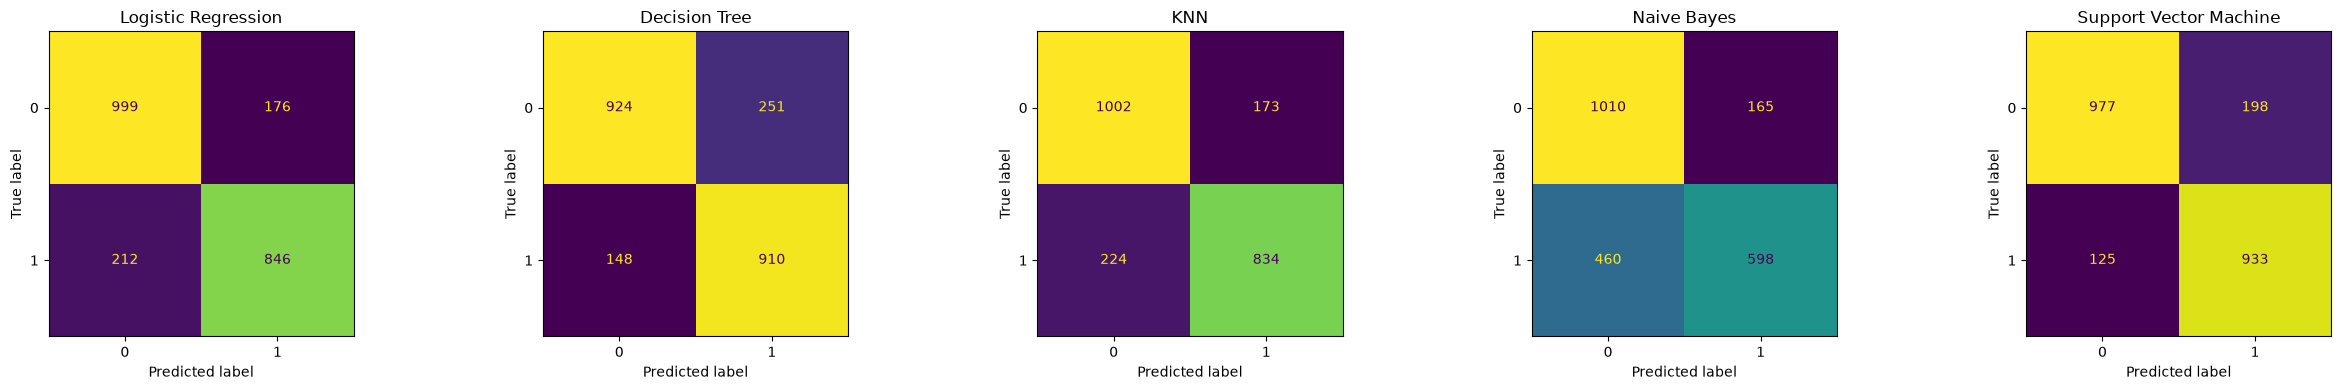

==================== Logistic Regression ====================
              precision    recall  f1-score   support

           0       0.82      0.85      0.84      1175
           1       0.83      0.80      0.81      1058

    accuracy                           0.83      2233
   macro avg       0.83      0.82      0.83      2233
weighted avg       0.83      0.83      0.83      2233

==================== Decision Tree ====================
              precision    recall  f1-score   support

           0       0.86      0.79      0.82      1175
           1       0.78      0.86      0.82      1058

    accuracy                           0.82      2233
   macro avg       0.82      0.82      0.82      2233
weighted avg       0.82      0.82      0.82      2233

==================== KNN ====================
              precision    recall  f1-score   support

           0       0.82      0.85      0.83      1175
           1       0.83      0.79      0.81      1058

    accuracy      

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(25, 4))
for ax, (name, pipe) in zip(axes, pipelines.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

for name, pipe in pipelines.items():
    print('=' * 20, name, '=' * 20)
    print(classification_report(y_test, pipe.predict(X_test), zero_division=0))

## 7. Save models and metrics

In [8]:
for name, pipe in pipelines.items():
    joblib.dump(pipe, MODEL_DIR / file_names[name])

with open(MODEL_DIR / 'metrics.json', 'w') as f:
    json.dump(results, f, indent=2)

print('Saved models to', MODEL_DIR)
print('Saved test data to', TEST_PATH)

Saved models to c:\Users\gssprabk\Downloads\ML_Project\model
Saved test data to c:\Users\gssprabk\Downloads\ML_Project\test_data.csv


## 8. Observations

- **Logistic Regression:** Balanced performance (Accuracy 0.826, AUC 0.907, F1 0.813). A linear decision boundary is a solid baseline for this data.
- **Decision Tree:** Highest recall among the single models (0.860) but lower precision (0.784), so it flags more clients as likely subscribers and produces more false positives. Max depth 8 limits overfitting.
- **KNN:** Accuracy 0.822 and AUC 0.888. Precision is good (0.828), but recall is lower (0.788). Distance-based, so it depends on the feature scaling done in the pipeline.
- **Naive Bayes:** Weakest model (Accuracy 0.720, MCC 0.447). Recall is only 0.565, so it misses many clients who subscribe. Its feature independence assumption does not fit this data well.
- **Support Vector Machine:** Best on most metrics (Accuracy 0.855, AUC 0.919, Recall 0.882, F1 0.852, MCC 0.712). The RBF kernel captures non-linear patterns.

**Overall winner:** Support Vector Machine. It has the highest Accuracy, AUC, Recall, F1, and MCC, and its precision (0.825) is close to the best value (0.828).